# Tarea - Análisis de Datos / Data Science 1

## Regresión

**Profesor:** Guillermo Cabrera Vives (guillecabrera@inf.udec.cl).<br>
**Ayudantes:** Miguel Sepúlveda González (msepulveda2017@udec.cl) y Felipe Burgos (felipeiburgos@inf.udec.cl).

En caso de dudas enviar correo con copia al profesor y a los ayudantes.

**Entrega:** La tarea se evaluará mediante un cuestionario presencial. Debe resolverla y traer este jupyter notebook con sus respuestas **impreso** el día del cuestionario, incluyendo el código, las respuestas y los resultados obtenidos. A su vez, debe subir este jupyter notebook resuelto a canvas.

**Fecha para subir tarea a canvas:** 28 de octubre, 2026, 23:59 hrs.

**Fecha del cuestionario:** 29 de octubre, 2026.

El cuestionario se basará en su tarea impresa e incluirá preguntas tanto de interpretación de los resultados como de comprensión del código utilizado. Por lo tanto, debe comprender y ser capaz de explicar las soluciones que haya desarrollado.

---

#### Normas del curso:
Antes de comenzar, lea detenidamente las normas que se aplicarán en esta evaluación.

- Debe asistir al cuestionario con su tarea resuelta e **impresa**. Asegúrese de que el código, las respuestas, las figuras y los resultados sean legibles.
- Cada respuesta debe ser explicada claramente, sin dejar espacio a dobles interpretaciones. **El código de la tarea debe estar comentado.**
- **No se pueden eliminar ni agregar bloques de código en el notebook proporcionado.** Debe completar los bloques existentes con las soluciones solicitadas.
- Está bien discutir las respuestas con compañeros/as. Está bien buscar información en internet. Está bien asistir a clases donde comentaremos cómo resolver la tarea. **No está bien** utilizar como solución código escrito por otras personas, ya sea por compañeros/as, obtenido de internet, tomado del código que el profesor programa en clases o generado con Inteligencia Artificial.
- **Todo código que escriba para resolver la tarea debe ser desarrollado completamente por usted.** De lo contrario, el alumno quedará con NCR (no cumple requisito).
- Las preguntas del cuestionario estarán relacionadas con su propia tarea. Debe poder explicar qué hace su código, justificar las decisiones tomadas e interpretar los resultados obtenidos.

---

### Objetivo:
Implementar el modelo de Regresión Lineal Bayesiana utilizando únicamente operaciones matriciales fundamentales. Deberán calcular analíticamente la distribución posterior de los parámetros y generar predicciones para nuevos datos.

#### Restricciones de Código:
* Prohibido el uso de librerías de machine learning o estadística (scikit-learn, statsmodels, PyMC, etc.).
* Permitido únicamente el uso de numpy (o la librería estándar de vectores/matrices de tu lenguaje) para operaciones de álgebra lineal básica (multiplicación de matrices, transposiciones e inversión).

In [2]:
# Puede usar solamente estas librerias
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as ss

# Índice

1. [Priors](#P1)

    [Pregunta 1](#P1.1)

2. [Posteriors](#P2)

    [Pregunta 2](#P2.1)

3. [Distribución Predictiva](#P3)

    [Pregunta 3.1](#P3.1)

    [Pregunta 3.2](#P3.2)

# Regresión Lineal Bayesiana

Considere un conjunto de datos $\mathcal{D}=\{(\boldsymbol{x}_i,y_i)\}_{i=1}^{N}$ y un modelo de regresión lineal en sus $k$ parámetros:

$$f(\boldsymbol{x}|\boldsymbol{\theta})=\sum_{p=1}^{k}\theta_p g_p(\boldsymbol{x})=\boldsymbol{g}(\boldsymbol{x})^\top\boldsymbol{\theta},$$

donde $\boldsymbol{g}(\boldsymbol{x})=(g_1(\boldsymbol{x}),\ldots,g_k(\boldsymbol{x}))^\top$ contiene las funciones de base.

En clases utilizamos la maximización del posterior para obtener estimaciones puntuales de los parámetros. En esta tarea modelaremos la distribución posterior de los coeficientes y la distribución predictiva para nuevas observaciones.

Supondremos que

$$y_i=f(\boldsymbol{x}_i|\boldsymbol{\theta})+\epsilon_i,$$

con errores independientes $\epsilon_i\sim\mathcal{N}(0,\sigma^2)$. **La varianza del ruido $\sigma^2$ es conocida y no debe estimarse.** Su valor se indicará en cada ejercicio. En el ejercicio final se proporcionarán desviaciones estándar conocidas para cada observación.

Utilizaremos un prior normal multivariado sobre los coeficientes:

$$p(\boldsymbol{\theta})=\mathcal{N}(\boldsymbol{\theta}|\boldsymbol{\mu}_\theta,C_\theta),$$

donde $\boldsymbol{\mu}_\theta$ es la media y $C_\theta$ es la matriz de covarianza del prior.


<a id="P1"></a>
# Parte 1: priors

<a id="P1.1"></a>
## Pregunta 1

Considere $k=2$, $\boldsymbol{\mu}_\theta=(0,0)^\top$ y

$$C_\theta=\begin{pmatrix}1&0\\0&1\end{pmatrix}.$$

### Pregunta 1.1
Grafique la distribución a priori conjunta $p(\boldsymbol{\theta})$ (gráfico de 2 dimensiones: $\boldsymbol{\theta} =  (\theta_1, \theta_2)$).

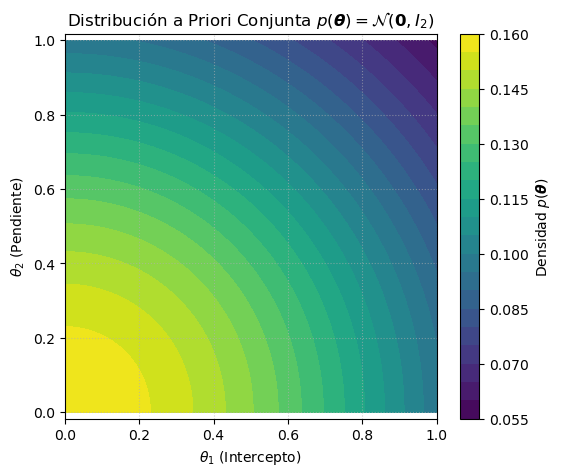

In [ ]:
# Grafique aquí el prior conjunto p(theta) de la Pregunta 1.1.

# Definimos la media y la matriz de covarianza del prior
mu = np.array([0, 0])
mc = np.eye(2)

# Creamos una grilla de puntos para theta_1 y theta_2
t1 = np.linspace(0, 1, 200)
t2 = np.linspace(0, 1, 200)
T1, T2 = np.meshgrid(t1, t2)
pos = np.dstack((T1, T2))

# Evaluamos la función de densidad de probabilidad normal multivariada
rv = ss.multivariate_normal(mu, mc)
z = rv.pdf(pos)

# Graficamos los contornos de la distribución conjunta
plt.figure(figsize=(6, 5))
contour = plt.contourf(T1, T2, z, levels=20, cmap="viridis")
plt.colorbar(contour, label="Densidad $p(\\boldsymbol{\\theta})$")
plt.xlabel("$\\theta_1$ (Intercepto)")
plt.ylabel("$\\theta_2$ (Pendiente)")
plt.title("Distribución a Priori Conjunta $p(\\boldsymbol{\\theta}) = \\mathcal{N}(\\boldsymbol{0}, I_2)$")
plt.grid(True, linestyle=":", alpha=0.6)
plt.axis("equal")
plt.show()

### Pregunta 1.2
¿Cómo interpreta este gráfico? Explique qué representan sus ejes y cómo se expresa la incertidumbre sobre los coeficientes antes de observar datos.

_Responda aquí_

# Parte 2: Posteriors

### Definición 1: Posterior con ruido homoscedastico

Considere la verosimilitud

$$p(y_i|\boldsymbol{x}_i,\boldsymbol{\theta},\sigma^2)=\mathcal{N}(y_i|\boldsymbol{g}(\boldsymbol{x}_i)^\top\boldsymbol{\theta},\sigma^2),$$

con $\sigma^2$ conocida, y el prior $p(\boldsymbol{\theta})=\mathcal{N}(\boldsymbol{\theta}|\boldsymbol{\mu}_\theta,C_\theta)$.

La distribución posterior de los coeficientes es

$$p(\boldsymbol{\theta}|\mathcal{D},\sigma^2)=\mathcal{N}(\boldsymbol{\theta}|\boldsymbol{\mu}_N,C_N),$$

donde

$$C_N=\left(C_\theta^{-1}+\frac{1}{\sigma^2}M^\top M\right)^{-1},$$

$$\boldsymbol{\mu}_N=C_N\left(C_\theta^{-1}\boldsymbol{\mu}_\theta+\frac{1}{\sigma^2}M^\top Y\right).$$

La matriz de diseño y el vector de observaciones son

$$M=\begin{pmatrix}
g_1(\boldsymbol{x}_1)&\cdots&g_k(\boldsymbol{x}_1)\\
g_1(\boldsymbol{x}_2)&\cdots&g_k(\boldsymbol{x}_2)\\
\vdots&&\vdots\\
g_1(\boldsymbol{x}_N)&\cdots&g_k(\boldsymbol{x}_N)
\end{pmatrix},\qquad
Y=\begin{pmatrix}y_1\\y_2\\\vdots\\y_N\end{pmatrix}.$$

Para simplificar la notación, también escribiremos $p(\boldsymbol{\theta}|\mathcal{D})$, manteniendo implícita la varianza conocida.

> **Nota:** Este resultado puede utilizarse directamente.


### Definición 2: Posterior con ruido heteroscedástico

Si cada observación tiene una desviación estándar conocida $e_i>0$, suponemos errores independientes $\epsilon_i\sim\mathcal{N}(0,e_i^2)$. Definimos

$$\Sigma=\operatorname{diag}(e_1^2,\ldots,e_N^2).$$

La verosimilitud conjunta es

$$p(Y|M,\boldsymbol{\theta},\Sigma)=\mathcal{N}(Y|M\boldsymbol{\theta},\Sigma).$$

Con el mismo prior normal de la Definición 1.1, el posterior es

$$p(\boldsymbol{\theta}|\mathcal{D},\Sigma)=\mathcal{N}(\boldsymbol{\theta}|\boldsymbol{\mu}_N,C_N),$$

con

$$C_N=(C_\theta^{-1}+M^\top\Sigma^{-1}M)^{-1},$$

$$\boldsymbol{\mu}_N=C_N(C_\theta^{-1}\boldsymbol{\mu}_\theta+M^\top\Sigma^{-1}Y).$$

Si todas las observaciones tienen la misma varianza conocida, $\Sigma=\sigma^2I_N$, se recupera la Definición 1. En ambos casos solo se infieren los coeficientes: la covarianza del ruido es un dato del problema.

> **Nota:** Use esta definición en el ejercicio final, donde se proporciona un vector de errores conocidos.


### Definición 3: Posteriors marginales de los coeficientes

Si el posterior conjunto de $\boldsymbol{\theta}$ es $\mathcal{N}(\boldsymbol{\mu}_N,C_N)$, el posterior marginal de cada coeficiente $\theta_j$ es

$$p(\theta_j|\mathcal{D})=\mathcal{N}(\theta_j|(\boldsymbol{\mu}_N)_j,(C_N)_{jj}),\qquad j=1,\ldots,k.$$

Su media es $(\boldsymbol{\mu}_N)_j$ y su desviación estándar es $\sqrt{(C_N)_{jj}}$. Los elementos fuera de la diagonal de $C_N$ describen la covarianza entre los coeficientes.

La marginal de un coeficiente se obtiene integrando sobre los demás coeficientes. La varianza del ruido permanece fija.


<a id="P2.1"></a>
## Pregunta 2

Considere los datos 1-D descritos a continuación y un modelo con $k=2$, $g_1(x)=1$ y $g_2(x)=x$. Utilice una varianza del ruido conocida $\sigma^2=1$ y el prior $\boldsymbol{\mu}_\theta=(0,0)^\top$, $C_\theta=I_2$.

### Pregunta 2.1
Calcule la media y la matriz de covarianza posterior usando la Definición 1.1. Programe y grafique los posteriors marginales de $\theta_1$ (intercepto) y $\theta_2$ (pendiente), de acuerdo con la Definición 1.3. Identifique claramente cada coeficiente en los gráficos.


In [ ]:
x = np.array([0.2, 1.3, 1.5, 1.8, 2.3, 4.2, 4.7, 4.9, 7.2, 8.1])
y = np.array([2.5, 3.8, 3.4, 5.1, 4.7, 7.1, 7.7, 7.9, 11, 11.7])

# Calcule y grafique aquí los posteriors marginales de ambos coeficientes.

# Varianza del ruido conocida y priors
sigma2 = 1.0
mu = np.array([0.0, 0.0])
mc = np.eye(2)
inv = np.linalg.inv(mc)

# Construcción de la matriz de diseño M (columna de 1s y columna de x)
M = np.column_stack([np.ones_like(x), x])
Y = y.reshape(-1, 1)

# Cálculo de la covarianza posterior C_N y media posterior mu_N (Definición 1.1)
C_N = np.linalg.inv(inv + (1.0 / sigma2) * (M.T @ M))
mu_N = C_N @ (inv @ mu.reshape(-1, 1) + (1.0 / sigma2) * (M.T @ Y))

# Parámetros de las distribuciones marginales (Definición 1.3)
mu_1, std_1 = mu_N[0, 0], np.sqrt(C_N[0, 0])
mu_2, std_2 = mu_N[1, 0], np.sqrt(C_N[1, 1])

# Graficación de las marginales
t1_vals = np.linspace(mu_1 - 4*std_1, mu_1 + 4*std_1, 200)
t2_vals = np.linspace(mu_2 - 4*std_2, mu_2 + 4*std_2, 200)

plt.figure(figsize=(12, 4))

# Marginal de theta_1
plt.subplot(1, 2, 1)
plt.plot(t1_vals, ss.norm.pdf(t1_vals, mu_1, std_1), 'b-', lw=2)
plt.title(f"Posterior Marginal $\\theta_1$ (Intercepto)\n$\\mu = {mu_1:.3f}$, $\\sigma = {std_1:.3f}$")
plt.xlabel("$\\theta_1$")
plt.ylabel("Densidad")
plt.grid(True, linestyle=":")

# Marginal de theta_2
plt.subplot(1, 2, 2)
plt.plot(t2_vals, ss.norm.pdf(t2_vals, mu_2, std_2), 'r-', lw=2)
plt.title(f"Posterior Marginal $\\theta_2$ (Pendiente)\n$\\mu = {mu_2:.3f}$, $\\sigma = {std_2:.3f}$")
plt.xlabel("$\\theta_2$")
plt.ylabel("Densidad")
plt.grid(True, linestyle=":")

plt.tight_layout()
plt.show()

### Pregunta 2.2

Repita el cálculo y grafique los posteriors marginales de ambos coeficientes para los siguientes datos. Mantenga el mismo prior y la misma varianza del ruido conocida, $\sigma^2=1$. Use escalas comparables a las del conjunto anterior.


In [ ]:
x = np.array([7.2, 8.1])
y = np.array([11, 11.7])

# Calcule y grafique aquí los posteriors marginales de ambos coeficientes.

# Varianza del ruido conocida y priors
sigma2 = 1.0
mu = np.array([0.0, 0.0])
mc = np.eye(2)
inv = np.linalg.inv(mc)

# Matriz de diseño M
M = np.column_stack([np.ones_like(x), x])
Y = y.reshape(-1, 1)

# Cálculo de C_N y mu_N (Definición 1.1)
C_N = np.linalg.inv(inv + (1.0 / sigma2) * (M.T @ M))
mu_N = C_N @ (inv @ mu.reshape(-1, 1) + (1.0 / sigma2) * (M.T @ Y))

# Parámetros de las distribuciones marginales (Definición 1.3)
mu_1, std_1 = mu_N[0, 0], np.sqrt(C_N[0, 0])
mu_2, std_2 = mu_N[1, 0], np.sqrt(C_N[1, 1])

# Graficación usando escalas comparables
t1_vals = np.linspace(-2, 6, 300)
t2_vals = np.linspace(-1, 3, 300)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t1_vals, ss.norm.pdf(t1_vals, mu_1, std_1), 'b-', lw=2)
plt.title(f"Posterior Marginal $\\theta_1$ (Intercepto) [$N=2$]\n$\\mu = {mu_1:.3f}$, $\\sigma = {std_1:.3f}$")
plt.xlabel("$\\theta_1$")
plt.ylabel("Densidad")
plt.grid(True, linestyle=":")

plt.subplot(1, 2, 2)
plt.plot(t2_vals, ss.norm.pdf(t2_vals, mu_2, std_2), 'r-', lw=2)
plt.title(f"Posterior Marginal $\\theta_2$ (Pendiente) [$N=2$]\n$\\mu = {mu_2:.3f}$, $\\sigma = {std_2:.3f}$")
plt.xlabel("$\\theta_2$")
plt.ylabel("Densidad")
plt.grid(True, linestyle=":")

plt.tight_layout()
plt.show()


### Pregunta 2.3

Compare la media y la dispersión posterior del intercepto y de la pendiente para ambos conjuntos de datos. ¿Cómo influyen la cantidad de observaciones y la distribución de sus valores de $x$ en la incertidumbre sobre los coeficientes?


_Responda aquí_

### Pregunta 2.4
Considere $k = 2$, $g_1(x) = (1)$ y $g_2(x) = x$ y los datos 1-D descritos a continuación. Utilizando el modelo Bayesiano de la Definición 1.1, grafique el posterior $p(\boldsymbol{\theta}|\{\boldsymbol{x}_i,y_i\}_{i=1}^N)$

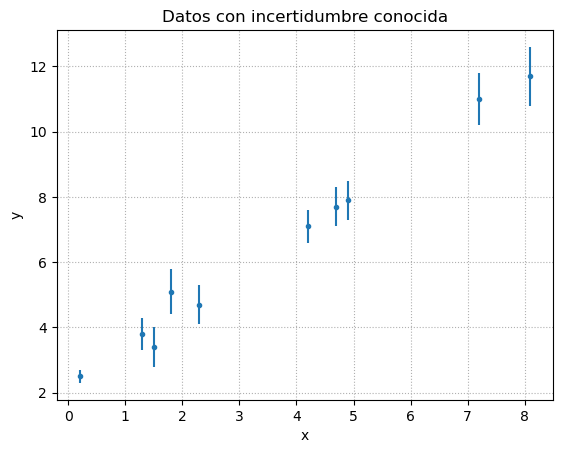

In [5]:
x = np.array([0.2, 1.3, 1.5, 1.8, 2.3, 4.2, 4.7, 4.9, 7.2, 8.1])
y = np.array([2.5, 3.8, 3.4, 5.1, 4.7, 7.1, 7.7, 7.9, 11, 11.7])
e = np.array([0.2, 0.5, 0.6, 0.7, 0.6, 0.5, 0.6, 0.6, 0.8, 0.9]) # error

plt.errorbar(x, y, yerr = e, ls = "", marker = ".")
plt.title("Datos con incertidumbre conocida")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linestyle=":")
plt.show()



# Parte 3: Distribución predictiva

### Definición 4: Distribución predictiva con varianza del ruido conocida

Para una nueva observación $y_*$ en un input $\boldsymbol{x}_*$, marginalizamos sobre los parámetros del modelo usando su distribución a-posteriori:

$$p(y_*|\boldsymbol{x}_*,\mathcal{D},\sigma^2)=\int p(y_*|\boldsymbol{x}_*,\boldsymbol{\theta},\sigma^2)\,p(\boldsymbol{\theta}|\mathcal{D},\sigma^2)\,d\boldsymbol{\theta}.$$

La distribución predictiva es normal:

$$p(y_*|\boldsymbol{x}_*,\mathcal{D},\sigma^2)=\mathcal{N}(y_*|\mu_*(\boldsymbol{x}_*),s_*^2(\boldsymbol{x}_*)),$$

con

$$\mu_*(\boldsymbol{x}_*)=\boldsymbol{g}(\boldsymbol{x}_*)^\top\boldsymbol{\mu}_N,$$

$$s_*^2(\boldsymbol{x}_*)=\sigma^2+\boldsymbol{g}(\boldsymbol{x}_*)^\top C_N\boldsymbol{g}(\boldsymbol{x}_*).$$

El primer término de la varianza corresponde al ruido de una nueva observación; el segundo corresponde a la incertidumbre sobre la función de regresión.

Para $m$ nuevos inputs, sea $M_*$ su matriz de diseño, con filas $\boldsymbol{g}(\boldsymbol{x}_*)^\top$. La **distribución predictiva** conjunta es

$$p(Y_*|M_*,\mathcal{D},\sigma^2)=\mathcal{N}(Y_*|M_*\boldsymbol{\mu}_N,\sigma^2I_m+M_*C_NM_*^\top).$$

Las desviaciones estándar predictivas se obtienen tomando la raíz cuadrada de la diagonal de esta matriz de covarianza. Para la incertidumbre de la función sin ruido de observación, se utiliza únicamente $M_*C_NM_*^\top$.

<a id="P3.1"></a>
## Pregunta 3.1

Programe una clase llamada `BLR`, que reciba la media y la covarianza del prior y utilice una varianza del ruido conocida. La clase deberá contener los siguientes métodos:

1. `fit`: calcular la media $\boldsymbol{\mu}_N$ y la matriz de covarianza $C_N$ del posterior usando la Definición 1.1, a partir de la matriz de diseño, las observaciones y la varianza conocida.
2. `posterior_theta`: obtener la distribución normal multivariada posterior de los coeficientes de la Definición 1.1.
3. `marginal_theta`: obtener la distribución normal marginal de un coeficiente seleccionado, de acuerdo con la Definición 1.3.
4. `predict`: calcular la distribución predictiva de la Definición 1.4 para una matriz de diseño de nuevos inputs.

La varianza del ruido se proporciona como un valor conocido y debe mantenerse fija. Complete el bloque de código siguiente con la implementación de la clase.


In [6]:
# Implemente aquí la clase BLR de la Pregunta 1.3.
# Métodos: fit, posterior_theta, marginal_theta y predict.

import numpy as np
import scipy.stats as ss

class BLR:
    def __init__(self, mu_theta, C_theta):
        """
        Inicializa la clase con la media y covarianza del prior.
        """

    def fit(self, M, Y, sigma2):
        """
        Calcula la media mu_N y la covarianza C_N del posterior usando la Definición 1.1.
        """

    def posterior_theta(self):
        """
        Retorna la distribución normal multivariada posterior de los coeficientes.
        """

    def marginal_theta(self, j):
        """
        Obtiene la distribución normal marginal del coeficiente theta_j (indexado desde 1 a k).
        De acuerdo con la Definición 1.3, retorna un objeto scipy.stats.norm.
        """

    def predict(self, M_star):
        """
        Calcula la distribución predictiva conjunta para una matriz de diseño de nuevos inputs M_star
        retornando la media y la desviación estándar para cada punto.
        """


<a id="P3.2"></a>
## Pregunta 3.2

Considere los siguientes conjuntos de datos muestreados desde una sinusoide. Utilizando la clase `BLR`, grafique la distribución predictiva de un modelo polinomial:

$$f(x|\boldsymbol{\theta})=\theta_1+\theta_2x+\cdots+\theta_kx^{k-1}.$$

Utilice $\boldsymbol{\mu}_\theta=\boldsymbol{0}_k$, $C_\theta=I_k$ y una varianza del ruido conocida $\sigma^2=0.04$, equivalente a una desviación estándar $\sigma=0.2$.

Puede elegir el grado del polinomio que estime conveniente, pero debe justificar su elección y utilizar el mismo grado para los tres conjuntos de datos. Recuerde que $k$ es el grado del polinomio más uno.


### Pregunta 3.2.1

Grafique el posterior para cada uno de los siguientes conjuntos de datos.

In [7]:
sigma2_seno = 0.04  # Varianza conocida del ruido para este ejercicio.

x1 =  np.array([0.9, 4. ])
y1 =  np.array([ 0.92, -0.74])

x2 =  np.array([2.66, 3.57, 4.73, 5.36, 0.55])
y2 =  np.array([ 0.51, -0.52, -1.02, -0.74,  0.44])

x3 =  np.array([2.54, 1.3 , 5.99, 2.06, 5.86, 3.95, 0.48, 0.52, 3.44, 4.04, 3.16,
       6.16, 6.17, 5.55, 2.94, 5.1 , 5.87, 5.39, 4.73, 3.08])
y3 =  np.array([ 0.52,  1.13, -0.28,  1.  , -0.41, -0.78,  0.38,  0.37, -0.2 ,
       -0.89, -0.06, -0.1 , -0.18, -0.58,  0.24, -0.92, -0.5 , -0.75,
       -1.08,  0.13])

# Puntos para evaluar la predicción
x_grid = np.linspace(0, np.pi * 2, 200)



### Pregunta 3.2.2

Compare la media y la dispersión del posterior para cada uno de los conjuntos de datos. ¿Cómo influyen la cantidad de observaciones y la distribución de sus valores de $x$ en la incertidumbre sobre los coeficientes?

_Escriba su respuesta aquí_

### Pregunta 3.2.3
Para cada conjunto, grafique los datos, y la distribución predictiva: la media predictiva y barras de error de una desviación estándar predictiva en una grilla de puntos del intervalo $[0,2\pi]$, usando el método `predict` de su clase `BLR`. Utilice escalas comparables entre los tres gráficos.



In [8]:
sigma2_seno = 0.04  # Varianza conocida del ruido para este ejercicio.

x1 =  np.array([0.9, 4. ])
y1 =  np.array([ 0.92, -0.74])

x2 =  np.array([2.66, 3.57, 4.73, 5.36, 0.55])
y2 =  np.array([ 0.51, -0.52, -1.02, -0.74,  0.44])

x3 =  np.array([2.54, 1.3 , 5.99, 2.06, 5.86, 3.95, 0.48, 0.52, 3.44, 4.04, 3.16,
       6.16, 6.17, 5.55, 2.94, 5.1 , 5.87, 5.39, 4.73, 3.08])
y3 =  np.array([ 0.52,  1.13, -0.28,  1.  , -0.41, -0.78,  0.38,  0.37, -0.2 ,
       -0.89, -0.06, -0.1 , -0.18, -0.58,  0.24, -0.92, -0.5 , -0.75,
       -1.08,  0.13])

# Puntos para evaluar la predicción
x_grid = np.linspace(0, np.pi * 2, 200)



### Pregunta 3.2.4
Analice qué está estimando el modelo y cómo cambia su incertidumbre según la cantidad y la ubicación de las observaciones. Distinga la incertidumbre sobre la función del ruido de una nueva observación.

_Responda aquí_